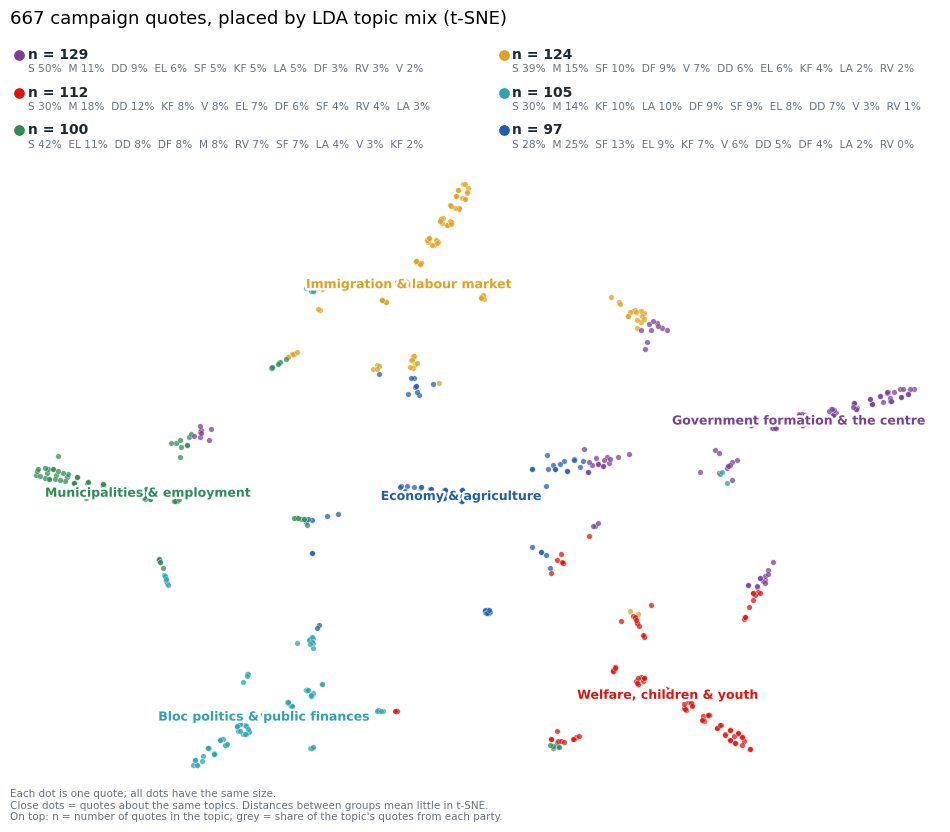

In [3]:
# --- t-SNE of the campaign quotes (LDA), same as the atlas – static version (English) ---
import ast
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.manifold import TSNE

project_root = Path("../..") 

# 1. Same data, stopwords and LDA as tfidf.ipynb, so the topics are the atlas topics
df = pd.read_csv(project_root / "data" / "tokenized_citater.csv")
df["tokens"] = df["tokens"].apply(lambda v: ast.literal_eval(v) if isinstance(v, str) else [])
df = df.dropna(subset=["parti"])
df = df[df["tokens"].map(len) > 0]
ord_pr_parti = df.groupby("parti")["tokens"].apply(lambda l: sum(map(len, l)))
valid_parties = ord_pr_parti[ord_pr_parti >= 100].index
custom_stopwords = ["sige", "mene", "udtale", "spørge", "svare", "fortælle", "kalde", "pege",
    "helt", "rigtig", "faktisk", "selvfølgelig", "god", "godt", "stor", "stort", "hel", "få", "gå", "tage", "se", "give",
    "komme", "blive", "gøre", "kunne", "ville", "skulle", "måtte", "når", "hvor", "hvordan", "fordi", "også", "bare",
    "lidt", "meget", "mange", "flere", "ny", "nyt", "nye", "dansk", "danmark", "parti", "partier", "politik", "politisk",
    "valgkamp", "valg", "folketingsvalg", "folk", "ting", "sag", "måde", "dag", "år", "gang", "tid", "del", "spørgsmål",
    "mette", "frederiksen", "lars", "løkke", "rasmussen", "jakob", "ellemann", "jensen", "søren", "pape", "poulsen",
    "pia", "olsen", "dyhr", "inger", "støjberg", "alex", "vanopslagh", "sofie", "carsten", "nielsen", "mai",
    "villadsen", "morten", "messerschmidt", "pernille", "vermund", "franciska", "rosenkilde"]
df_lda = df[df["parti"].isin(valid_parties)].copy()
df_lda = df_lda[df_lda["tokens"].map(len) >= 5].reset_index(drop=True)
count_vec = CountVectorizer(min_df=5, max_df=0.50, stop_words=custom_stopwords)
dtm = count_vec.fit_transform(df_lda["tokens"].apply(" ".join))
lda = LatentDirichletAllocation(n_components=6, random_state=42, max_iter=25)
theta = lda.fit_transform(dtm)
theta = theta / theta.sum(1, keepdims=True)
df_lda["emne"] = theta.argmax(1)

TOPICS = ["Economy & agriculture", "Immigration & labour market", "Municipalities & employment",
          "Government formation & the centre", "Welfare, children & youth", "Bloc politics & public finances"]
EMNE_FARVER = ["#1F5FAD", "#E3A01F", "#2E8B57", "#7B3F98", "#E3120B", "#2BA3B4"]          # atlas colours

# 2. t-SNE exactly as in the atlas: Hellinger distance = Euclidean distance on sqrt(theta)
xy = TSNE(n_components=2, perplexity=min(30, (len(df_lda) - 1) / 3), metric="euclidean", init="pca",
          learning_rate="auto", random_state=42).fit_transform(np.sqrt(theta))
df_lda["x"], df_lda["y"] = xy[:, 0], xy[:, 1]

# 3. Draw: topic legend with all numbers on top, the labelled map below
orden = list(df_lda["emne"].value_counts().index)                       # largest topic first
N = len(df_lda)
andel = pd.crosstab(df_lda["emne"], df_lda["parti"], normalize="index")
fig = plt.figure(figsize=(12, 9.6))
gs = fig.add_gridspec(2, 1, height_ratios=[0.2, 1], hspace=0.0)
top, ax = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

# top: one entry per topic – small dot + name, share of all quotes, and who says it
top.axis("off"); top.set_xlim(-0.01, 2.1); top.set_ylim(-0.05, 1)
for k, i in enumerate(orden):
    x, y = 1.1 * (k % 2), 0.9 - 0.32 * (k // 2)
    n = int((df_lda["emne"] == i).sum())
    top.scatter(x + 0.01, y, s=45, color=EMNE_FARVER[i])
    top.text(x + 0.03, y, f"n = {n}", fontsize=10, fontweight="bold", color="#1f2933", va="center")
    hvem = andel.loc[i].sort_values(ascending=False)
    top.text(x + 0.03, y - 0.12, "  ".join(f"{p} {v:.0%}" for p, v in hvem.items()), fontsize=7.6,
             color="#66717d", va="center")

# map (as before: topic names written on the groups)
for i, f in enumerate(EMNE_FARVER):
    d = df_lda[df_lda["emne"] == i]
    ax.scatter(d["x"], d["y"], s=16, color=f, alpha=0.75, linewidths=0.3, edgecolors="white")
    kerne = d.loc[((d[["x", "y"]] - d[["x", "y"]].median()) ** 2).sum(1).nsmallest(max(5, len(d) // 3)).index]
    ax.text(kerne["x"].median(), kerne["y"].median(), TOPICS[i], ha="center", va="center", fontsize=9,
            fontweight="bold", color=f, path_effects=[pe.withStroke(linewidth=3.5, foreground="white")])
ax.margins(x=0.03, y=0.03)
ax.set_xticks([]); ax.set_yticks([])
for s_ in ax.spines.values():
    s_.set_visible(False)
ax.text(0, -0.01, "Each dot is one quote; all dots have the same size.\n"
        "Close dots = quotes about the same topics. Distances between groups mean little in t-SNE.\n"
        "On top: n = number of quotes in the topic; grey = share of the topic's quotes from each party.",
        transform=ax.transAxes, fontsize=7.5, color="#66717d", va="top")

fig.suptitle(f"{N} campaign quotes, placed by LDA topic mix (t-SNE)", fontsize=13, x=0.125, ha="left", y=0.915)
fig.savefig(project_root / "docs" / "assets" / "figures" / "fig_citater_tsne.png", dpi=300, bbox_inches="tight")
plt.show()


In [4]:
fig.savefig("fig_citater_tsne.png", dpi=300, bbox_inches="tight")
fig.savefig("fig_citater_tsne.pdf", bbox_inches="tight")
plt.show()

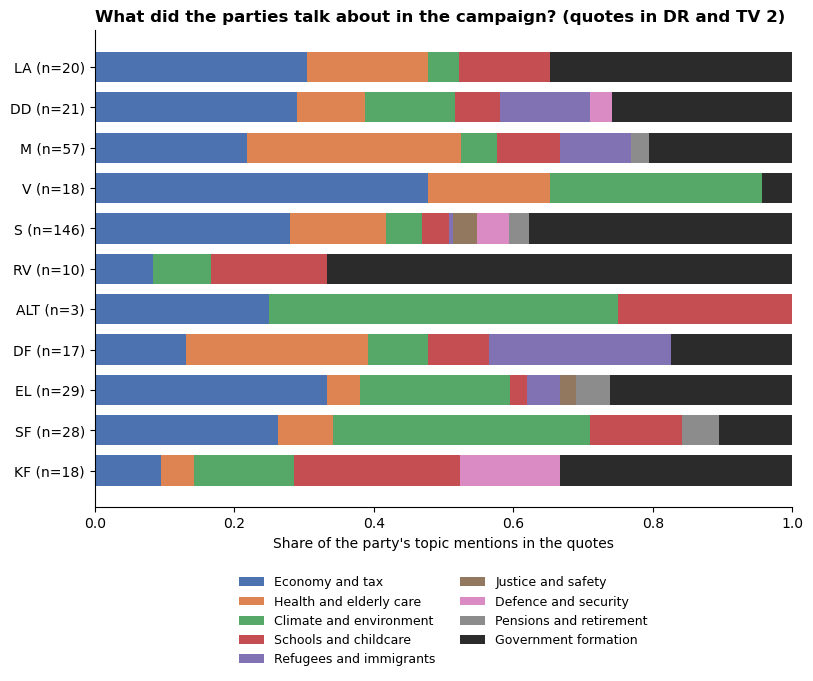

In [6]:
# --- What did the parties talk about in the campaign? (quotes in DR and TV 2) ---
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path("../..")
citater = pd.read_csv(project_root / "data" / "citater_pr_politiker.csv").dropna(subset=["parti"])

# 1. The same 8 topics (keyword stems) as the mærkesager in Figure 1, plus government formation
#    "ord" = word starts with it · "*ord" = may appear inside a word · "=ord" = exactly that word
TOPICS = {
    "Economy and tax": ["økonomi", "*skat", "afgift", "inflation", "*pris", "vækst", "virksomhed", "erhverv",
        "iværksætter", "fradrag", "regning", "elafgift", "bureaukrati", "arbejdsmarked", "løn"],
    "Health and elderly care": ["sundhed", "sygehus", "hospital", "sygeplejersk", "*læge", "*venteliste", "ventetid",
        "psykiatri", "patient", "behandling", "ældre", "plejehjem", "hjemmehjælp", "ældrepleje"],
    "Climate and environment": ["forurening", "*klima", "grøn", "co2", "vedvarende", "*energiforsyning", "energikrise",
        "energipolitik", "vindmølle", "solcelle", "atomkraft", "fossil", "udledning", "omstilling", "landbrug", "miljø",
        "natur", "biodiversitet", "dyrevelfærd", "drikkevand", "vandmiljø", "grundvand"],
    "Schools and childcare": ["kultur", "*skole", "uddannelse", "*gymnasi", "elever", "studerende", "=su",
        "daginstitution", "børnehave", "vuggestue", "pædagog", "normering", "minimumsnormering", "lærer",
        "universitet", "faglært"],
    "Refugees and immigrants": ["udlænding", "*asyl", "flygtning", "indvandr", "integration", "statsborgerskab",
        "hjemsend", "udvis", "familiesammenfør", "islam", "muslim", "grænsekontrol", "opholdstilladelse"],
    "Justice and safety": ["kriminal", "straf", "=politi", "=politiet", "politibetjent", "vold", "bande", "fængsel",
        "domstol", "retssikkerhed", "retsstat", "retspolitik", "terror"],
    "Defence and security": ["forsvar", "nato", "militær", "soldat", "værnepligt", "sikkerhedspolitik", "ukraine",
        "rusland", "=krig", "beredskab"],
    "Pensions and retirement": ["pension", "efterløn", "=arne", "seniorpension", "tilbagetrækning", "pensionist"],
    "Government formation": ["regering", "statsminist", "midte", "*blok", "forhandl", "samarbejd"],
}
COLOURS = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860", "#DA8BC3", "#8C8C8C", "#2B2B2B"]

def matches(word, stem):
    if stem.startswith("="):
        return word == stem[1:]
    if stem.startswith("*"):
        return stem[1:] in word
    return word.startswith(stem)

def topics_in(text):
    """Which topics does a quote mention? (one quote can mention several)"""
    words = re.findall(r"[a-zæøåé0-9]+", str(text).lower())
    return [t for t, stems in TOPICS.items() if any(matches(w, s) for w in words for s in stems)]

citater["topics"] = citater["citat"].apply(topics_in)
mentions = citater[["parti", "topics"]].explode("topics").dropna(subset=["topics"]).reset_index(drop=True)

# 2. Share of each party's topic mentions; n = number of quotes that mention at least one topic
PARTIES = ["KF", "SF", "EL", "DF", "ALT", "RV", "S", "V", "M", "DD", "LA"]          # bottom to top
share = pd.crosstab(mentions["parti"], mentions["topics"], normalize="index").reindex(index=PARTIES, columns=list(TOPICS), fill_value=0)
n = citater[citater["topics"].map(len) > 0]["parti"].value_counts()

# 3. Draw
fig, ax = plt.subplots(figsize=(9, 6.2))
left = np.zeros(len(PARTIES))
for topic, colour in zip(TOPICS, COLOURS):
    ax.barh(range(len(PARTIES)), share[topic].values, left=left, color=colour, height=0.75, label=topic)
    left += share[topic].values
ax.set_yticks(range(len(PARTIES)), [f"{p} (n={n.get(p, 0)})" for p in PARTIES])
ax.set_xlim(0, 1)
ax.set_xlabel("Share of the party's topic mentions in the quotes")
ax.set_title("What did the parties talk about in the campaign? (quotes in DR and TV 2)", fontsize=12,
             fontweight="bold", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(ncol=2, frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.savefig(project_root / "docs" / "assets" / "figures" / "fig3_citater_emner.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
fig.savefig("fig_citater_emner.png", dpi=300, bbox_inches="tight")
fig.savefig("fig_citater_emner.pdf", bbox_inches="tight")
plt.show()

# Validating the klacification

In [8]:
# --- Stikprøve til manuel validering af citater ---

# Afgræns til partierne i figuren
population = citater[citater["parti"].isin(PARTIES)].copy()

# Opdel efter om citatet har fået mindst ét emne
population["classified"] = population["topics"].map(len) > 0

# Udtræk 60 citater fra hver gruppe
samples = []

for classified, group in population.groupby("classified"):
    sample = group.sample(n=60, random_state=42).copy()

    # Beregn samplingvægt
    sample["sampling_weight"] = len(group) / len(sample)

    samples.append(sample)

# Saml og bland stikprøven
sample = (
    pd.concat(samples)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

sample["validation_id"] = range(1, len(sample) + 1)

# Gem klassifikationen separat
validation_key = sample[
    ["validation_id", "topics", "sampling_weight"]
].copy()

validation_key["predicted_topics"] = (
    validation_key["topics"].apply("|".join)
)

validation_key = validation_key.drop(columns="topics")

# Opret fil til manuel validering uden modellens svar
validation = sample[
    ["validation_id", "parti", "citat"]
].copy()

validation["manual_topics"] = ""
validation["comment"] = ""

# Gem filer i notebookens arbejdsmappe
OUTPUT = Path.cwd()

validation.to_csv(
    OUTPUT / "manual_validation_quotes.csv",
    index=False,
    sep=";",
    encoding="utf-8-sig"
)

validation_key.to_csv(
    OUTPUT / "quote_validation_key.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Population:", len(population))
print("Sample size:", len(sample))
print("\nSample distribution:")
display(sample["classified"].value_counts())


Population: 749
Sample size: 120

Sample distribution:


classified
False    60
True     60
Name: count, dtype: int64

Validated quotes: 120
Exact match accuracy: 0.742


,precision,recall,f1-score,support,manual_n,predicted_n
Economy and tax,1.000,0.635,0.777,240.800,39.0,25.0
Health and elderly care,0.867,0.926,0.895,85.883,14.0,15.0
Climate and environment,0.778,1.000,0.875,42.817,7.0,9.0
Schools and childcare,0.889,1.000,0.941,48.933,8.0,9.0
Refugees and immigrants,1.000,1.000,1.000,24.467,4.0,4.0
Justice and safety,0.000,0.000,0.000,12.733,2.0,0.0
Defence and security,0.750,0.590,0.661,31.083,5.0,4.0
Pensions and retirement,0.000,0.000,0.000,0.000,0.0,0.0
Government formation,0.615,0.722,0.664,67.783,11.0,13.0
micro avg,0.861,0.750,0.802,554.500,NaN,NaN


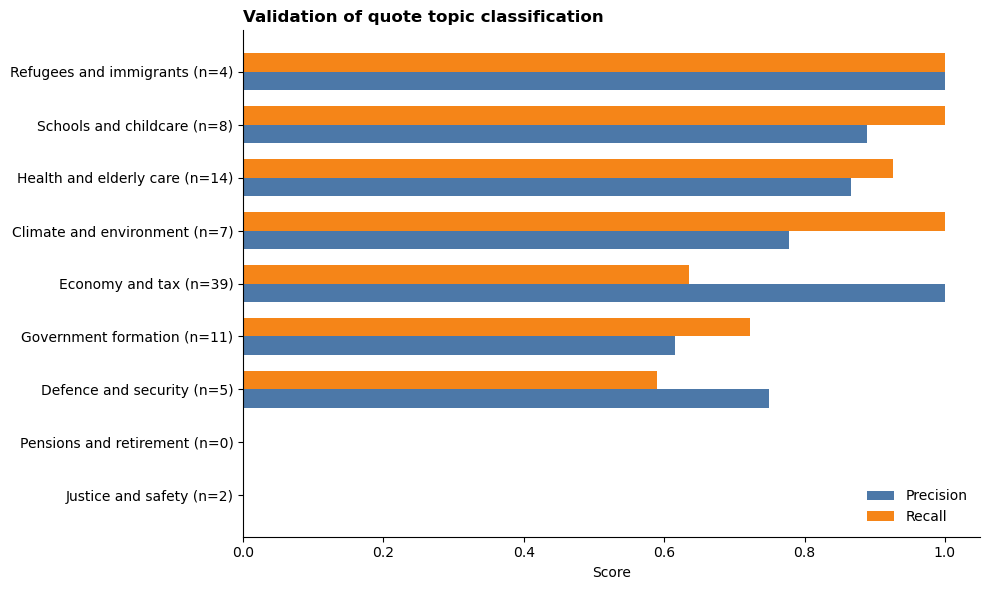

In [9]:
# --- Evaluering af manuel multi-label-validering ---

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import classification_report, accuracy_score

# 1. Indlæs manuel validering og automatisk klassifikation
annotated = pd.read_csv(
    OUTPUT / "manual_validation_quotes_sdn.csv",
    sep=";",
    encoding="utf-8-sig",
    keep_default_na=False
)

annotated.columns = annotated.columns.str.strip()

validation_key = pd.read_csv(
    OUTPUT / "quote_validation_key.csv",
    keep_default_na=False
)

results = annotated.merge(
    validation_key,
    on="validation_id",
    how="inner",
    validate="one_to_one"
)

# 2. Kontrollér at alle citater er manuelt valideret
assert len(results) == 120
assert results["manual_topics"].str.strip().ne("").all(), \
    "Der mangler manuelle annoteringer"

# 3. Konvertér emner til lister
def parse_topics(value):
    return [
        topic.strip()
        for topic in str(value).split("|")
        if topic.strip().lower() not in ["", "none"]
    ]

manual = results["manual_topics"].apply(parse_topics)
predicted = results["predicted_topics"].apply(parse_topics)

categories = list(TOPICS)

# Kontrollér kategorier
invalid_topics = (
    set(manual.explode().dropna())
    | set(predicted.explode().dropna())
) - set(categories)

assert not invalid_topics, f"Ukendte kategorier: {invalid_topics}"

# 4. Konvertér til binære emnematricer
mlb = MultiLabelBinarizer(classes=categories)

y_true = mlb.fit_transform(manual)
y_pred = mlb.transform(predicted)

weights = results["sampling_weight"].astype(float)

# 5. Beregn vægtede evalueringsmål
report = classification_report(
    y_true,
    y_pred,
    target_names=categories,
    sample_weight=weights,
    output_dict=True,
    zero_division=0
)

summary = pd.DataFrame(report).T

# Tilføj faktiske antal i stikprøven
summary["manual_n"] = pd.Series(
    y_true.sum(axis=0), index=categories
)

summary["predicted_n"] = pd.Series(
    y_pred.sum(axis=0), index=categories
)

# 6. Beregn exact match accuracy
exact_accuracy = accuracy_score(
    y_true,
    y_pred,
    sample_weight=weights
)

print("Validated quotes:", len(results))
print(f"Exact match accuracy: {exact_accuracy:.3f}")

display(summary.round(3))

# 7. Visualisér precision og recall
plot_data = summary.loc[categories].sort_values("f1-score")

fig, ax = plt.subplots(figsize=(10, 6))

y = np.arange(len(plot_data))
height = 0.35

ax.barh(
    y - height / 2,
    plot_data["precision"],
    height,
    label="Precision",
    color="#4C78A8"
)

ax.barh(
    y + height / 2,
    plot_data["recall"],
    height,
    label="Recall",
    color="#F58518"
)

ax.set_yticks(
    y,
    [
        f"{topic} (n={int(row['manual_n'])})"
        for topic, row in plot_data.iterrows()
    ]
)

ax.set_xlim(0, 1.05)
ax.set_xlabel("Score")
ax.set_title(
    "Validation of quote topic classification",
    fontweight="bold",
    loc="left"
)

ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")

fig.tight_layout()

fig.savefig(
    OUTPUT / "quote_validation_precision_recall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

NMI = 0.115, null 0.045, p < 0.001; 364 citater (49% af alle), 463 emne-omtaler
Håndkodning: precision 88%, recall 75% (n = 120 citater)


feat NOT subset; don't know how to subset; dropped
fond NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


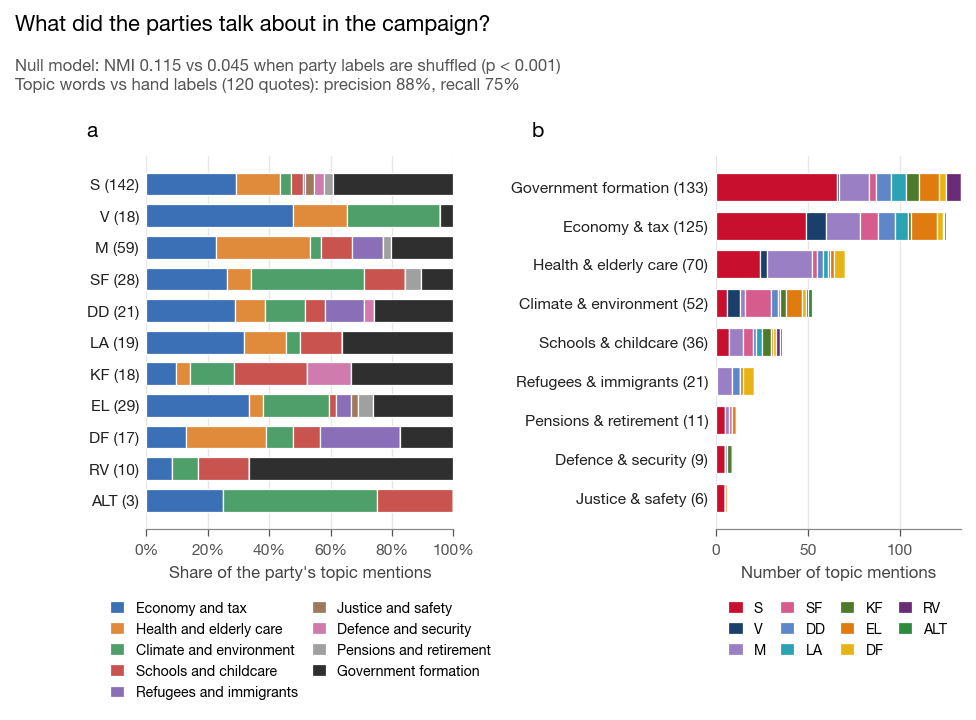

In [10]:
# --- FIGUR 4b · Hvad talte partierne om i valgkampen? (ny stil + validering) ---
# Indsæt i HvadDeSiger.ipynb i stedet for den gamle figur 4b-celle. Kræver stil.py i notebooks/.
import re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import normalized_mutual_info_score as nmi
sys.path.append("..")
from stil import *

DATA = "../../data/"

# 1. Emner via ordliste ("ord" = ord der starter med det · "*ord" = må stå inde i et ord · "=ord" = præcis det ord)
EMNER_ORD = {
    "Economy and tax": ["økonomi", "*skat", "afgift", "inflation", "*pris", "vækst", "virksomhed", "erhverv",
        "iværksætter", "fradrag", "regning", "elafgift", "bureaukrati", "arbejdsmarked", "løn"],
    "Health and elderly care": ["sundhed", "sygehus", "hospital", "sygeplejersk", "*læge", "*venteliste", "ventetid",
        "psykiatri", "patient", "behandling", "ældre", "plejehjem", "hjemmehjælp", "ældrepleje"],
    "Climate and environment": ["forurening", "*klima", "grøn", "co2", "vedvarende", "*energiforsyning", "energikrise",
        "energipolitik", "vindmølle", "solcelle", "atomkraft", "fossil", "udledning", "omstilling", "landbrug", "miljø",
        "natur", "biodiversitet", "dyrevelfærd", "drikkevand", "vandmiljø", "grundvand"],
    "Schools and childcare": ["kultur", "*skole", "uddannelse", "*gymnasi", "elever", "studerende", "=su",
        "daginstitution", "børnehave", "vuggestue", "pædagog", "normering", "minimumsnormering", "lærer",
        "universitet", "faglært"],
    "Refugees and immigrants": ["udlænding", "*asyl", "flygtning", "indvandr", "integration", "statsborgerskab",
        "hjemsend", "udvis", "familiesammenfør", "islam", "muslim", "grænsekontrol", "opholdstilladelse"],
    "Justice and safety": ["kriminal", "straf", "=politi", "=politiet", "politibetjent", "vold", "bande", "fængsel",
        "domstol", "retssikkerhed", "retsstat", "retspolitik", "terror"],
    "Defence and security": ["forsvar", "nato", "militær", "soldat", "værnepligt", "sikkerhedspolitik", "ukraine",
        "rusland", "=krig", "beredskab"],
    "Pensions and retirement": ["pension", "efterløn", "=arne", "seniorpension", "tilbagetrækning", "pensionist"],
    "Government formation": ["regering", "statsminist", "midte", "*blok", "forhandl", "samarbejd"],
}

def matches(word, stem):
    if stem.startswith("="):
        return word == stem[1:]
    if stem.startswith("*"):
        return stem[1:] in word
    return word.startswith(stem)

# Ord der ligner et emne, men ikke er det (fundet ved at læse citaterne):
IKKE_EMNE = {"naturligvis", "naturlige", "naturligt",          # ikke "natur" -> klima
             "voldsom", "voldsomme", "voldsomt",               # ikke "vold" -> kriminalitet
             "forsvarlig", "forsvarligt", "forsvare", "forsvarens"}  # ikke militært forsvar

def topics_in(text):
    """Which topics does a quote mention? (one quote can mention several)"""
    words = [w for w in re.findall(r"[a-zæøåé0-9]+", str(text).lower()) if w not in IKKE_EMNE]
    return [t for t, stems in EMNER_ORD.items() if any(matches(w, s) for w in words for s in stems)]


citater = pd.read_csv(DATA + "citater_pr_politiker.csv").dropna(subset=["parti"])
# Partiet under valgkampen 2022 (citatfilen har partiet i dag). Vermund var NB -> falder ud, fordi NB ikke er i PARTIER
PARTI_2022 = {"Pernille Vermund": "NB", "Mads Fuglede": "V", "Jon Stephensen": "M"}
citater["parti"] = citater["politiker"].map(PARTI_2022).fillna(citater["parti"])
citater = citater[citater["parti"].isin(PARTIER)].copy()
citater["topics"] = citater["citat"].apply(topics_in)
c = citater[citater["topics"].map(len) > 0].reset_index(drop=True)
m = c[["parti", "topics"]].explode("topics").reset_index()               # én række pr. emne-omtale
n_citater = c["parti"].value_counts()
andel = pd.crosstab(m["parti"], m["topics"], normalize="index").reindex(index=PARTIER, columns=EMNE_ORDEN, fill_value=0)
antal = pd.crosstab(m["topics"], m["parti"]).reindex(columns=PARTIER, fill_value=0)

# 2. VALIDERING (uge 2): bland hvem der sagde hvert citat, 1000 gange
nmi_rigtig = nmi(m["parti"], m["topics"])
rng = np.random.default_rng(0)
nmi_null = np.array([nmi(rng.permutation(c["parti"].values)[m["index"]], m["topics"]) for _ in range(1000)])
p = p_vaerdi(nmi_rigtig, nmi_null, "hoejere")
print(f"NMI = {nmi_rigtig:.3f}, null {nmi_null.mean():.3f}, {p_tekst(p)}; {len(c)} citater ({len(c) / len(citater):.0%} af alle), {len(m)} emne-omtaler")

# 3. VALIDERING (uge 8): ordlisten mod Signes håndkodning af 120 citater (60 med emne, 60 uden, vægtet)
from sklearn.metrics import precision_score, recall_score
from sklearn.preprocessing import MultiLabelBinarizer
haand = pd.read_csv("manual_validation_quotes_sdn.csv", sep=";", encoding="utf-8-sig", keep_default_na=False)
haand.columns = haand.columns.str.strip()
haand = haand.merge(pd.read_csv("quote_validation_key.csv", keep_default_na=False), on="validation_id")
emner_liste = lambda v: [t.strip() for t in str(v).split("|") if t.strip().lower() not in ("", "none")]
mlb = MultiLabelBinarizer(classes=list(EMNER_ORD))
y_haand = mlb.fit_transform(haand["manual_topics"].apply(emner_liste))
y_ord = mlb.transform(haand["citat"].apply(topics_in))                      # samme ordliste som i figuren
vaegt = haand["sampling_weight"].astype(float)
y_vaegt = np.repeat(vaegt.values[:, None], y_haand.shape[1], axis=1).ravel()
precision = precision_score(y_haand.ravel(), y_ord.ravel(), sample_weight=y_vaegt, zero_division=0)
recall = recall_score(y_haand.ravel(), y_ord.ravel(), sample_weight=y_vaegt, zero_division=0)
print(f"Håndkodning: precision {precision:.0%}, recall {recall:.0%} (n = {len(haand)} citater)")

# 3. Tegn
fig = plt.figure(figsize=(BREDDE, 8.2 * CM))
gs = fig.add_gridspec(1, 2, width_ratios=[1.25, 1], wspace=0.95)
ax, bx = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

orden = [p_ for p_ in PARTIER if p_ in n_citater.index]
venstre = np.zeros(len(orden))
for t in EMNE_ORDEN:
    v = andel.loc[orden, t].values
    ax.barh(range(len(orden)), v, left=venstre, color=EMNE_FARVE[t], height=0.72, edgecolor="white", linewidth=0.6, label=t)
    venstre += v
ax.set_yticks(range(len(orden)), [f"{p_} ({n_citater[p_]})" for p_ in orden])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Share of the party's topic mentions")
panel(ax, "a", x=-0.16)
ax.legend(ncol=2, loc="upper left", bbox_to_anchor=(-0.16, -0.16), fontsize=6.8)

ant = antal.loc[antal.sum(axis=1).sort_values().index]
venstre = np.zeros(len(ant))
for p_ in PARTIER:
    bx.barh(range(len(ant)), ant[p_].values, left=venstre, color=PARTI_FARVE[p_], height=0.72, edgecolor="white", linewidth=0.6, label=p_)
    venstre += ant[p_].values
bx.set_yticks(range(len(ant)), [f"{t.replace(' and ', ' & ')} ({int(ant.loc[t].sum())})" for t in ant.index])
bx.set_xlabel("Number of topic mentions")
panel(bx, "b", x=-0.7)
bx.legend(ncol=4, loc="upper left", bbox_to_anchor=(0.0, -0.16), fontsize=6.8)

titel(fig, "What did the parties talk about in the campaign?",
      f"Null model: NMI {nmi_rigtig:.3f} vs {nmi_null.mean():.3f} when party labels are shuffled ({p_tekst(p)})\n"
      f"Topic words vs hand labels ({len(haand)} quotes): precision {precision:.0%}, recall {recall:.0%}")
gem(fig, "fig4b_citater_emner")
plt.show()
